# Check for spikes in the altitude, wind, and pressure data
Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

DELTA_ALT_THRESH = 25 # (m) the altitude spike threshold
DELTA_ALT_THRESH_JUMP = 50 # (m) the altitude jump threshold
DELTA_WIND_THRESH = 1/30 # (m/s**2) the wind spike threshold
DELTA_P_THRESH = 1 # (hPa) the pressure spike threshold

In [2]:
# Load in the data
flights = pd.read_feather('Strateole2_with_ERA5_3_depressurizations.feather')
flights

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure,segment_id
0,C0_01_STR1,2019-11-12 22:25:07.005612,-4.834385,55.593623,20306.0,NaN,NaN,53.838274,203.450854,0.000698,8.270000,0
1,C0_01_STR1,2019-11-12 22:25:37.076783,-4.836663,55.593735,20297.0,0.361103,-8.387708,53.902477,203.418927,0.000698,8.270000,0
2,C0_01_STR1,2019-11-12 22:26:07.026208,-4.838898,55.593818,20297.0,0.256162,-8.362772,53.893533,203.423377,0.000698,8.200000,0
3,C0_01_STR1,2019-11-12 22:26:37.098505,-4.841163,55.593873,20305.0,0.200608,-8.576493,53.804733,203.467518,0.000698,8.200000,0
4,C0_01_STR1,2019-11-12 22:27:07.047890,-4.843513,55.593927,20306.0,0.188386,-8.961514,53.773176,203.483186,0.000698,8.770000,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3665364,C1_17_TTL3,2022-10-16 12:31:57.000000,-2.211255,125.868032,18601.4,-3.421231,2.695646,71.513419,NaN,NaN,10.187500,74
3665365,C1_17_TTL3,2022-10-16 12:32:27.000000,-2.210570,125.867093,18591.3,-3.461483,2.463263,71.650113,NaN,NaN,9.933594,74
3665366,C1_17_TTL3,2022-10-16 12:32:57.000000,-2.209930,125.866168,18597.9,-3.272620,2.364113,71.578122,NaN,NaN,9.821289,74
3665367,C1_17_TTL3,2022-10-16 12:33:27.000000,-2.209298,125.865332,18611.9,-2.845354,2.463263,71.404752,NaN,NaN,9.756836,74


  0%|          | 0/57 [00:00<?, ?it/s]

Number of altitude spikes: 110


/var/folders/dw/3jtpv5j16bv77dfbt2nw04780000gp/T/ipykernel_41067/301689454.py:31: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(15,4))


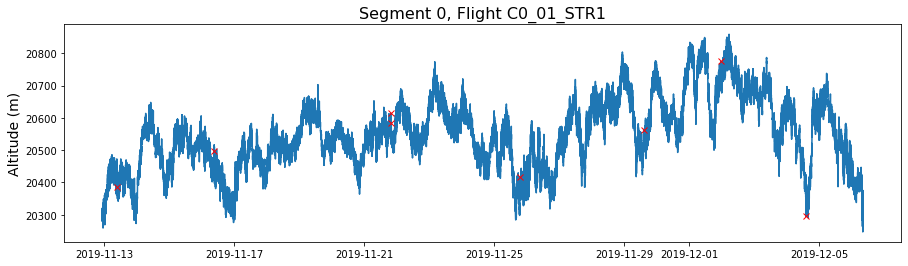

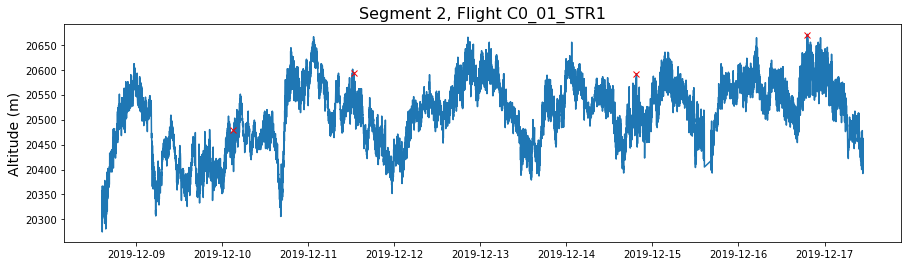

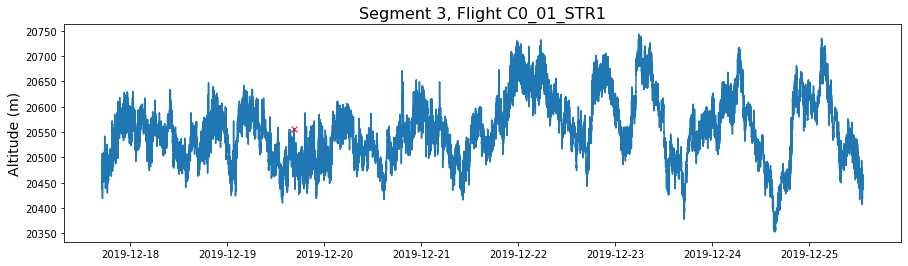

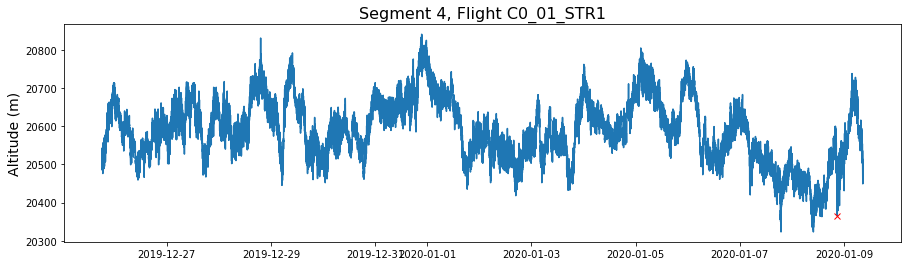

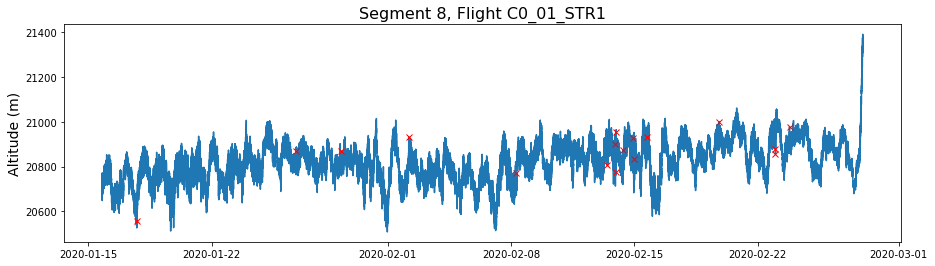

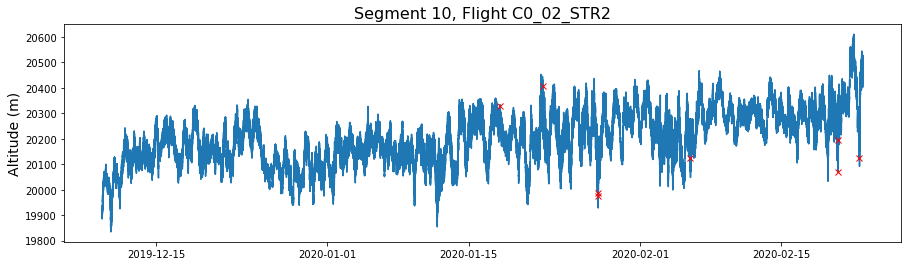

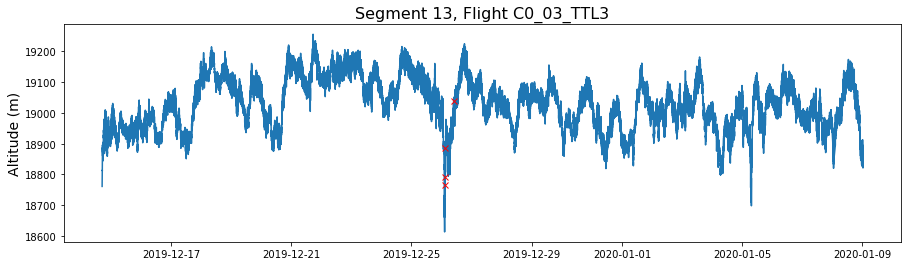

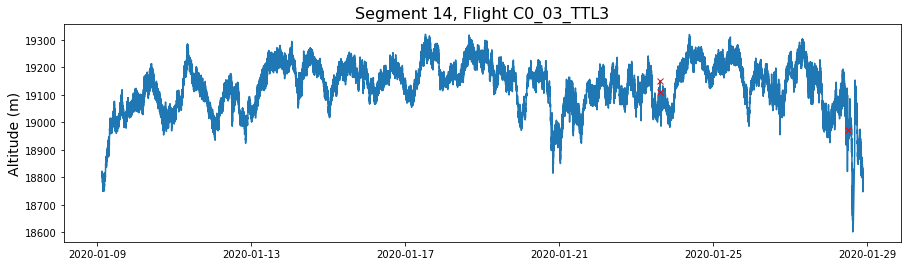

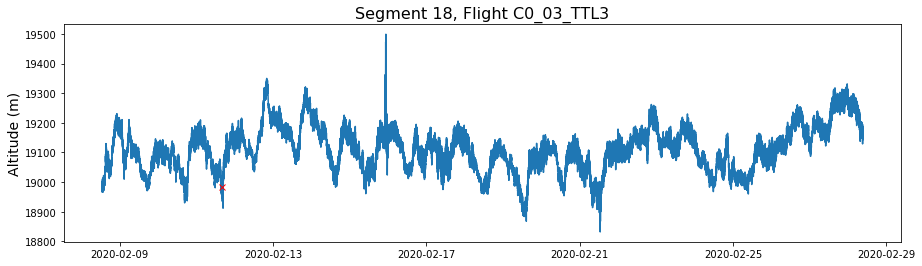

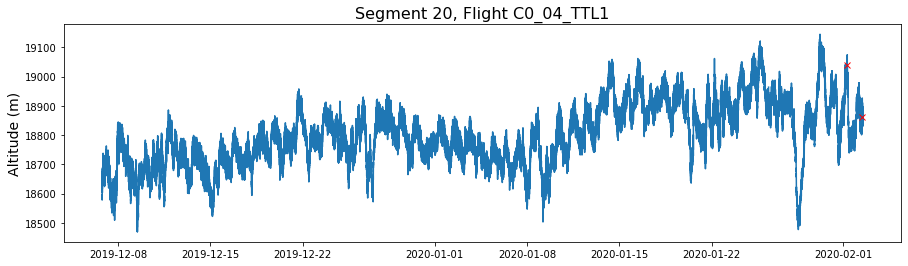

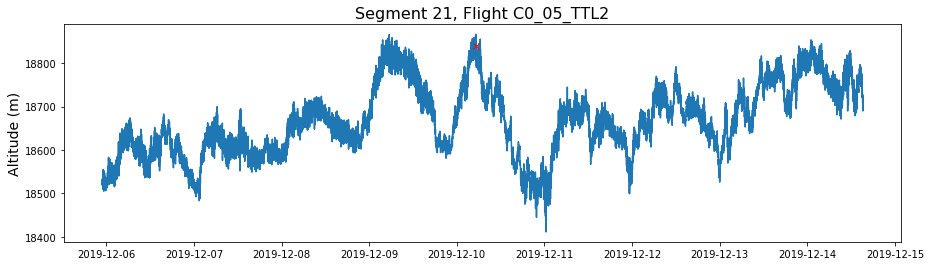

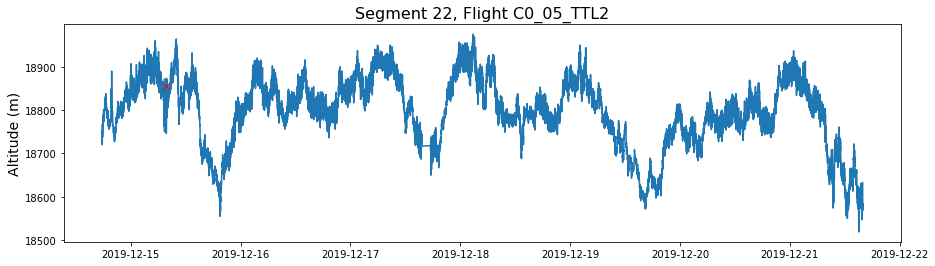

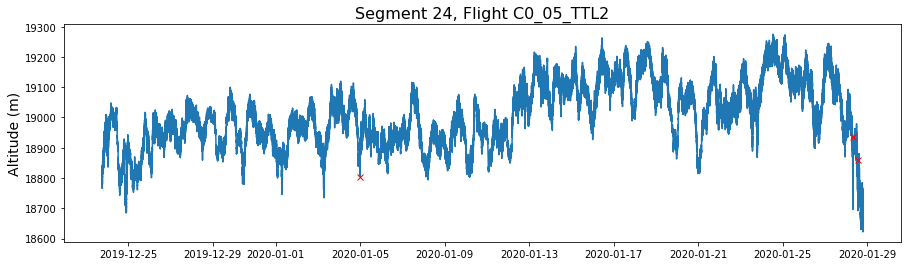

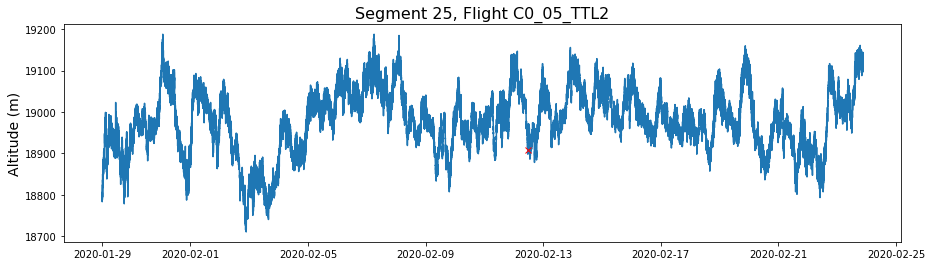

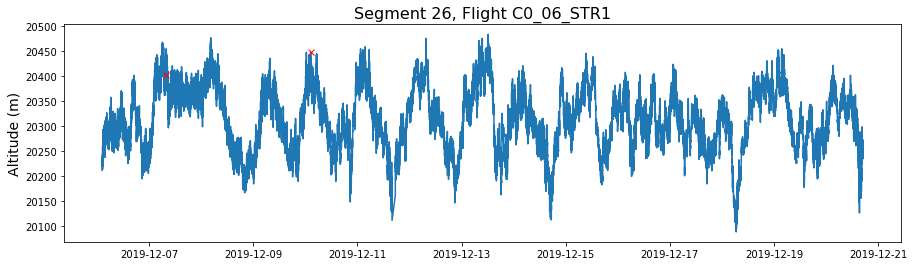

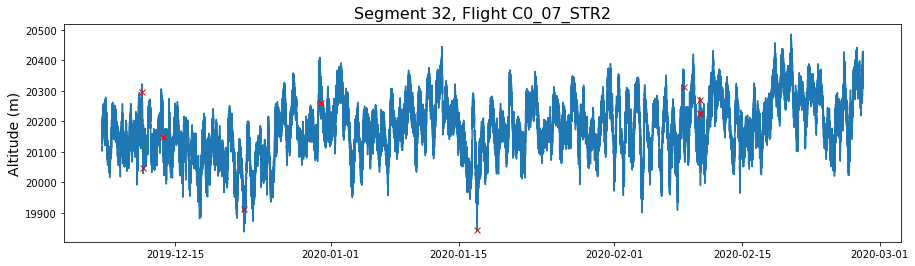

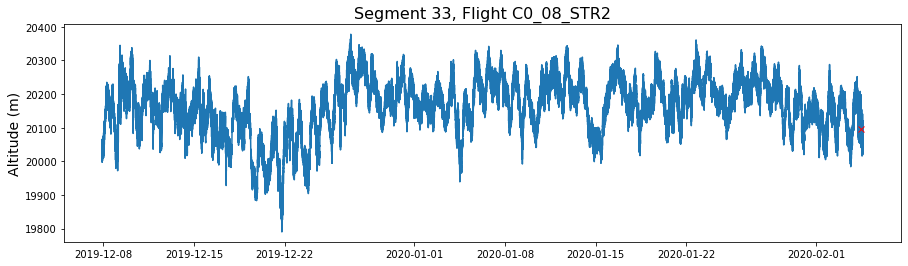

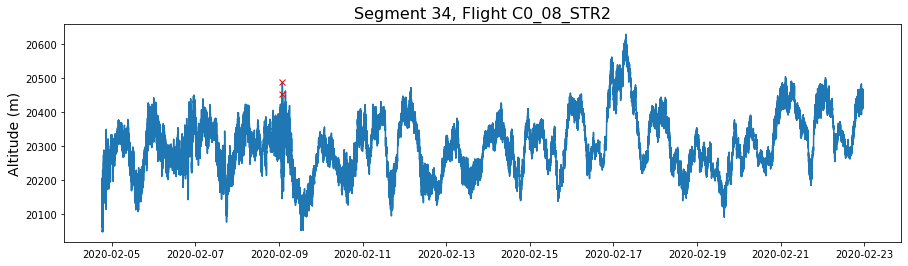

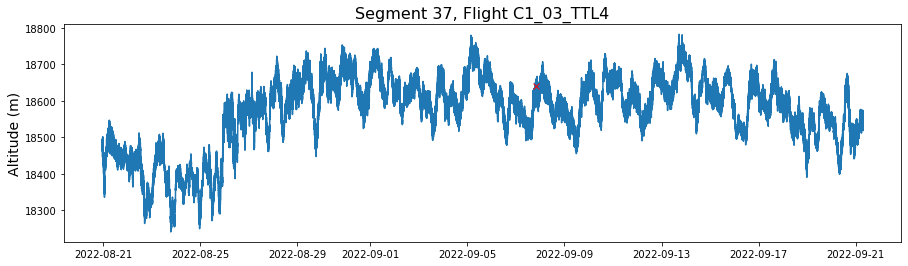

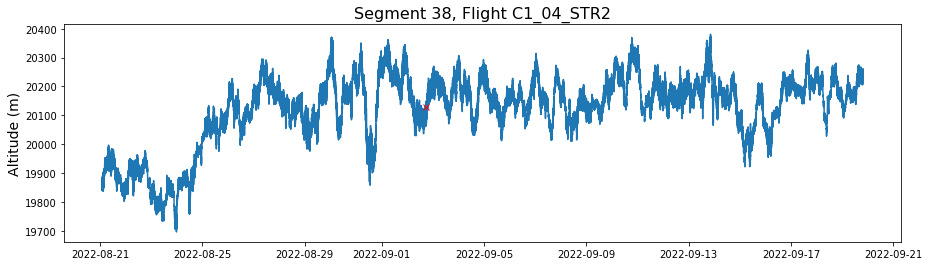

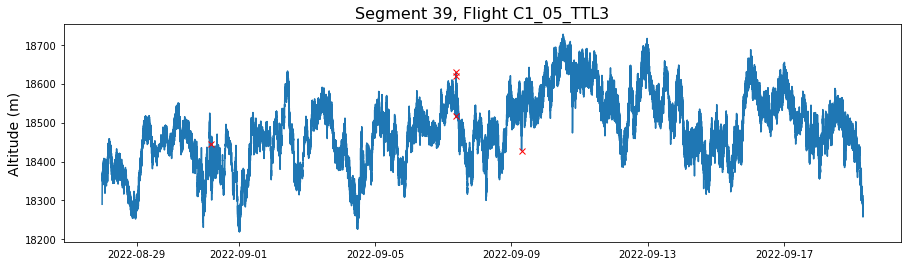

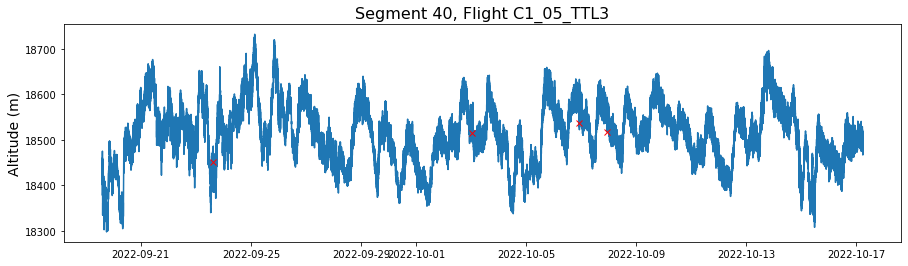

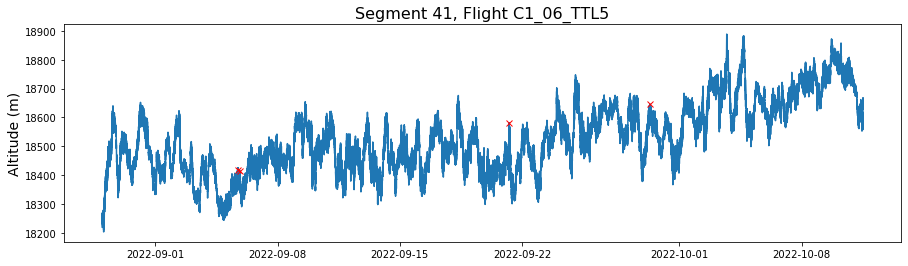

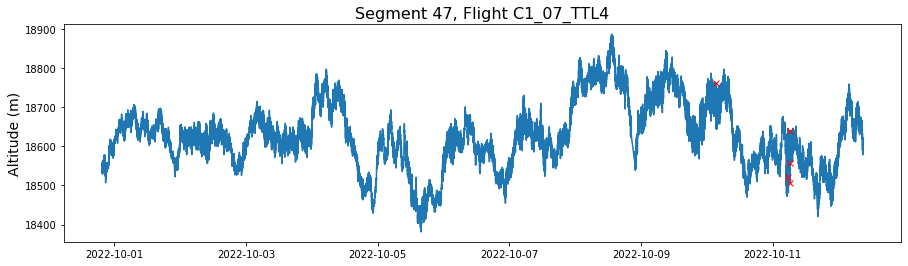

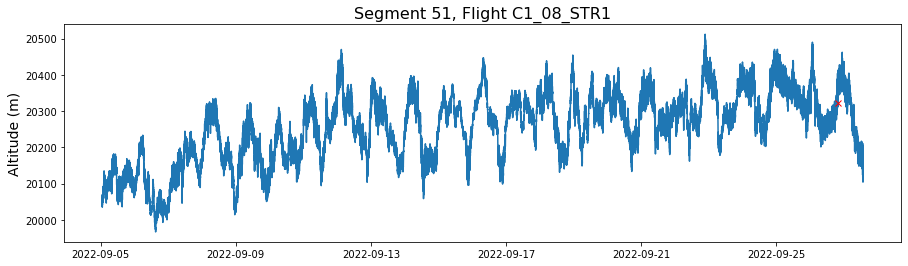

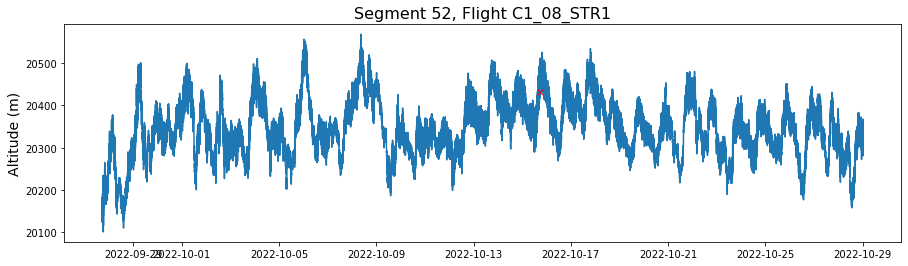

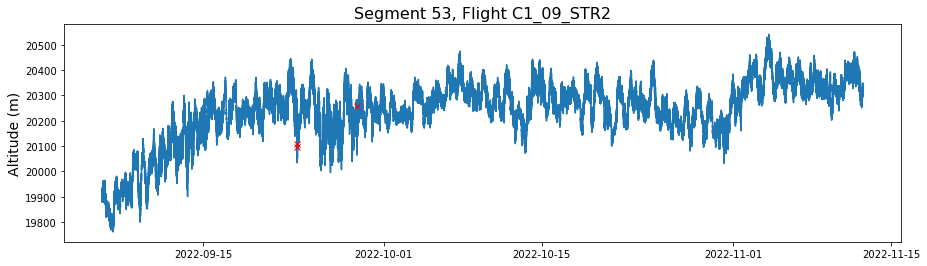

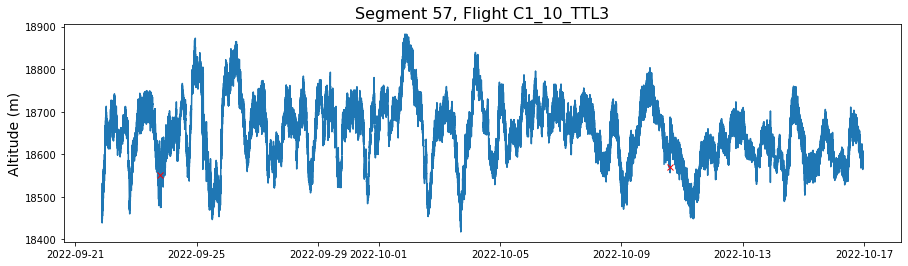

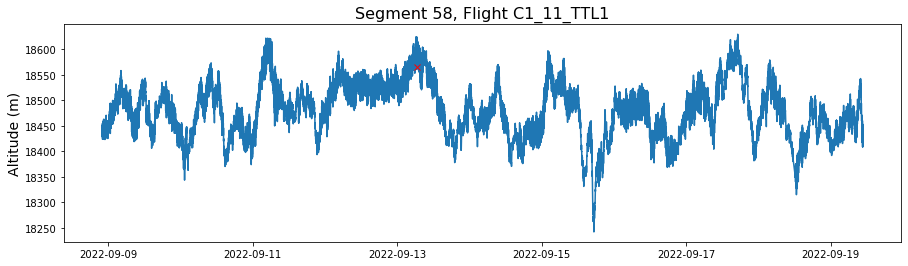

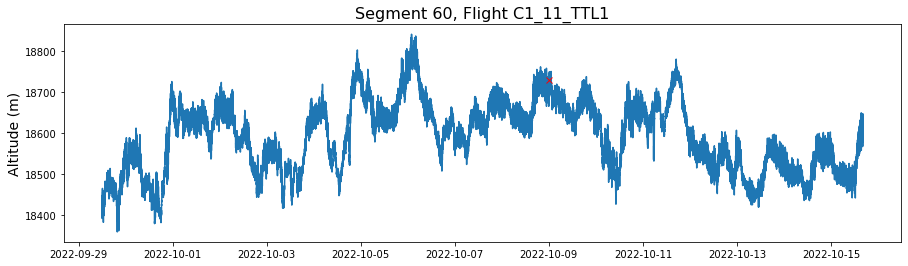

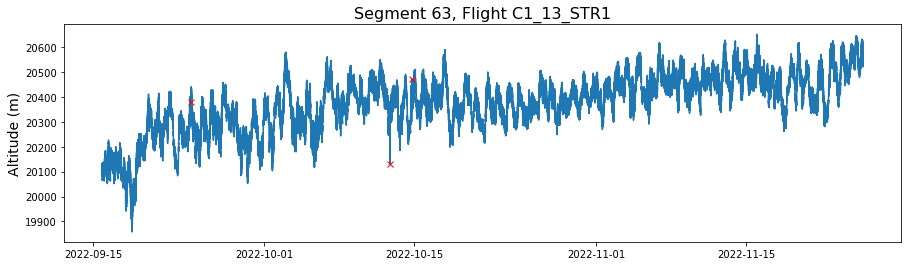

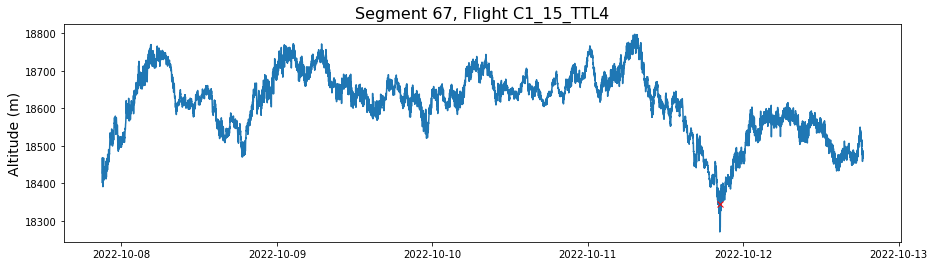

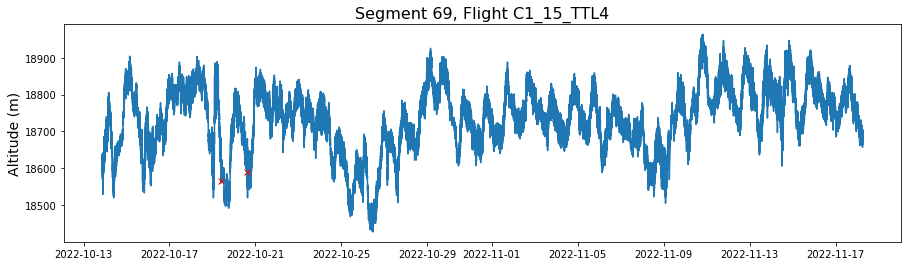

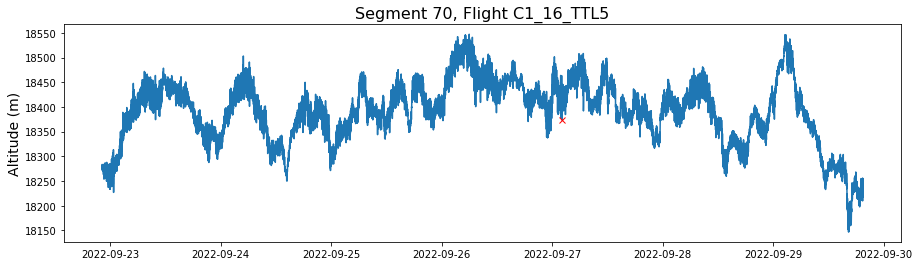

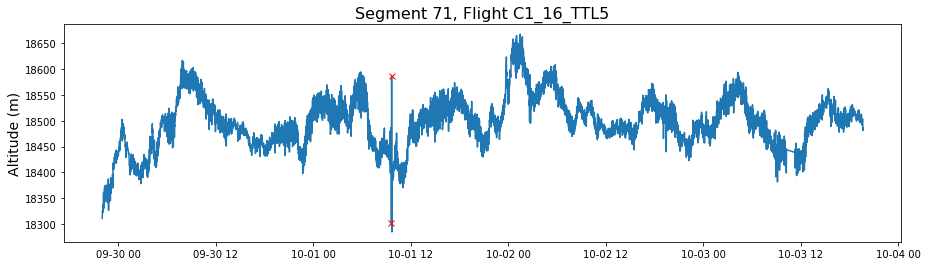

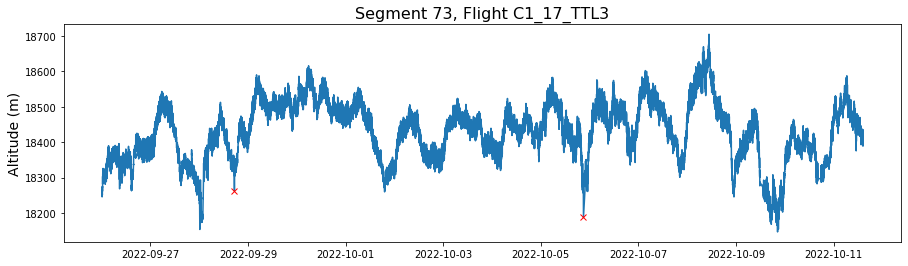

In [3]:
# Check for altitude spikes

def single_altitude_spike(segment):
    
    # Shift the values one time step so the second diff operates on the time step after a given value
    segment_shifted = segment.shift(periods=-1, axis="rows")
    # An increase from the previous value, then a decrease to the next value
    alt_change1 = segment.loc[(segment.altitude.diff() > DELTA_ALT_THRESH) & 
                              (segment_shifted.altitude.diff() < -DELTA_ALT_THRESH)]
    # A decrease from the previous value, then an increase to the next value
    alt_change2 = segment.loc[(segment.altitude.diff() < -DELTA_ALT_THRESH) & 
                              (segment_shifted.altitude.diff() > DELTA_ALT_THRESH)]
    # Mark the altitude spike
    segment['altitude_spike'] = 0
    segment.loc[alt_change1.index,['altitude_spike']] = 1
    segment.loc[alt_change2.index,['altitude_spike']] = 1
    
    return segment

temp = flights.reset_index(drop=True)
flights = flights.groupby('segment_id').progress_apply(single_altitude_spike).reset_index(drop=True)

print('Number of altitude spikes:', flights.altitude_spike.sum())

# Plot the altitude spikes
segments_to_plot = flights[flights.altitude_spike == 1].copy()
segments_to_plot = segments_to_plot.segment_id.unique()
for i in np.arange(segments_to_plot.size):
    segment = flights[flights.segment_id == segments_to_plot[i]]
    
    plt.figure(figsize=(15,4))
    plt.plot(segment.time,segment.altitude)
    temp = segment[segment.altitude_spike == 1]
    plt.plot(temp.time,temp.altitude,'rx')
    plt.title(f'Segment {segment.segment_id.iloc[0]}, Flight {segment.flight_id.iloc[0]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14);

  0%|          | 0/57 [00:00<?, ?it/s]

Number of altitude jumps: 872


/var/folders/dw/3jtpv5j16bv77dfbt2nw04780000gp/T/ipykernel_41067/1676321456.py:26: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(15,4))


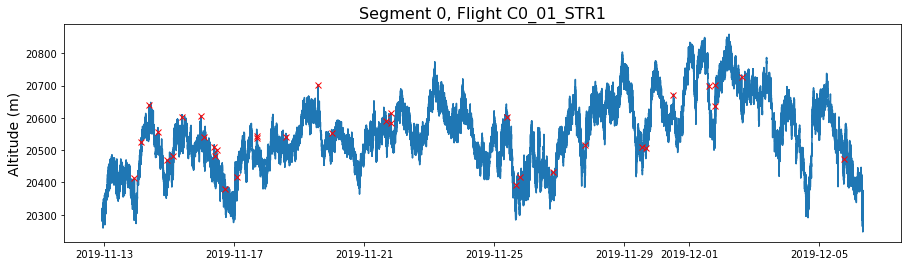

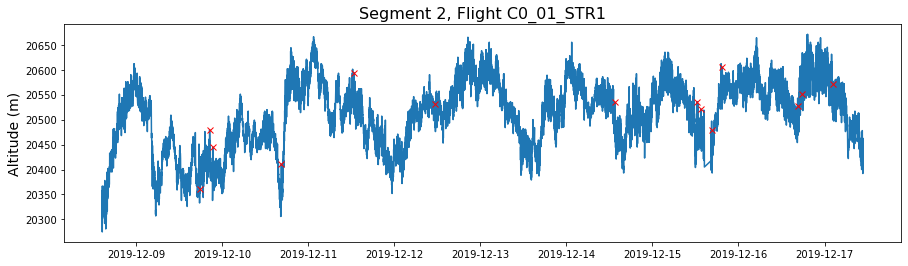

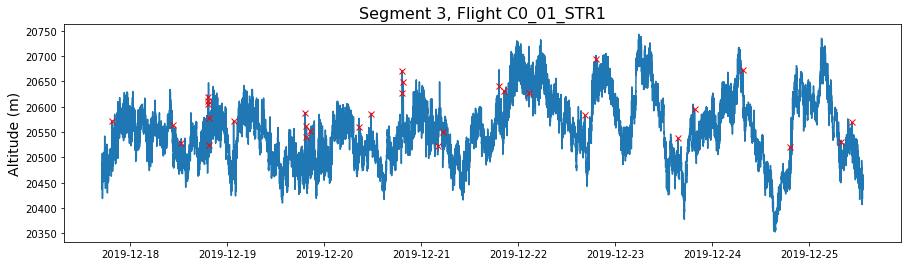

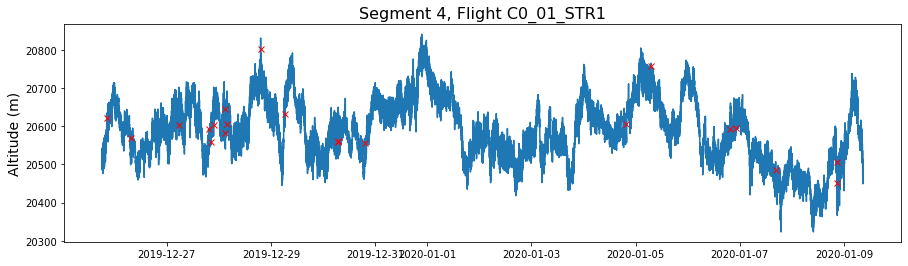

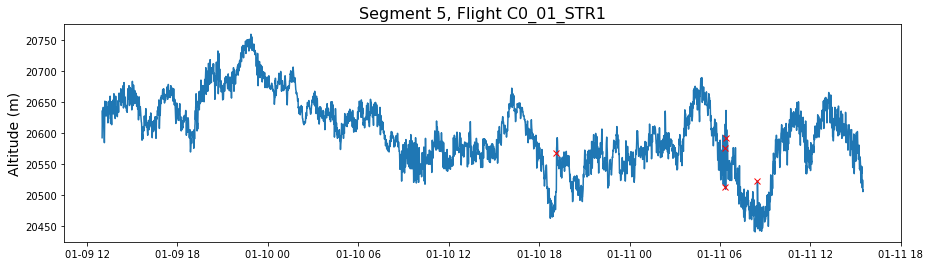

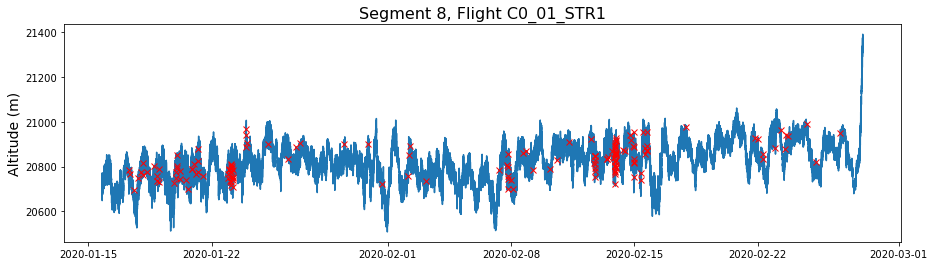

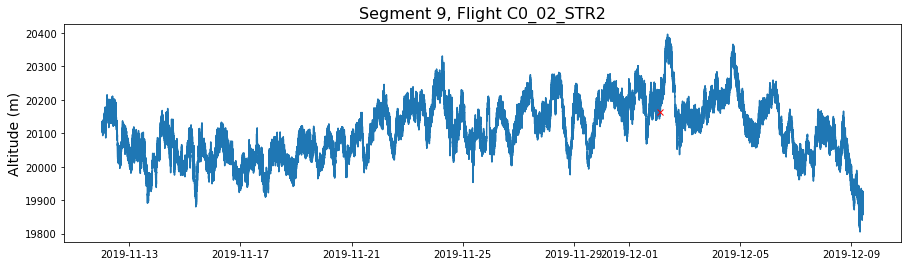

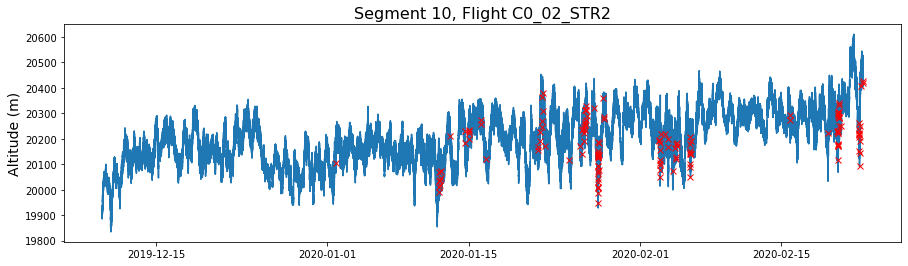

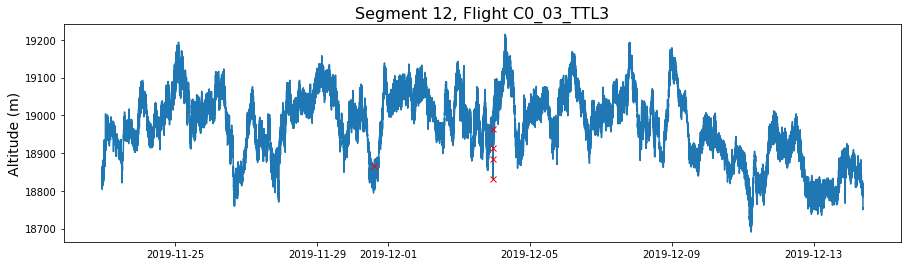

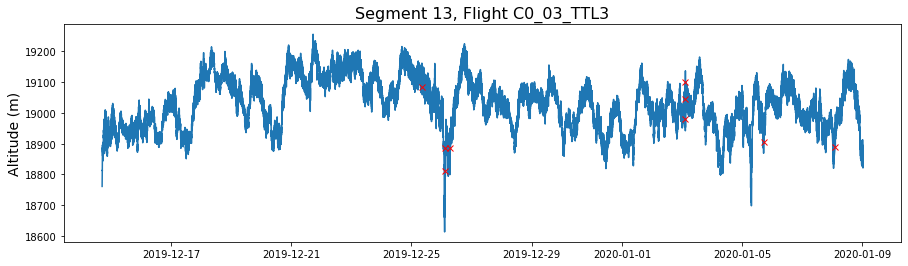

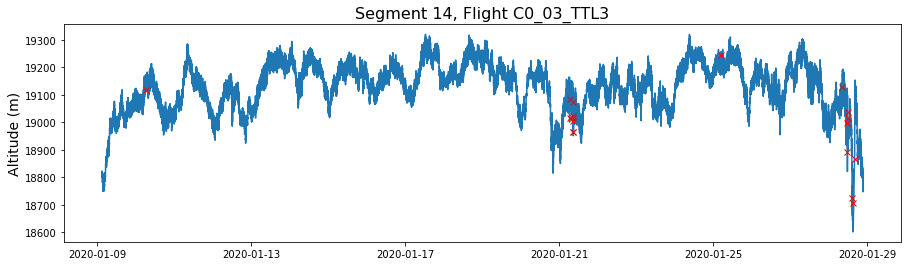

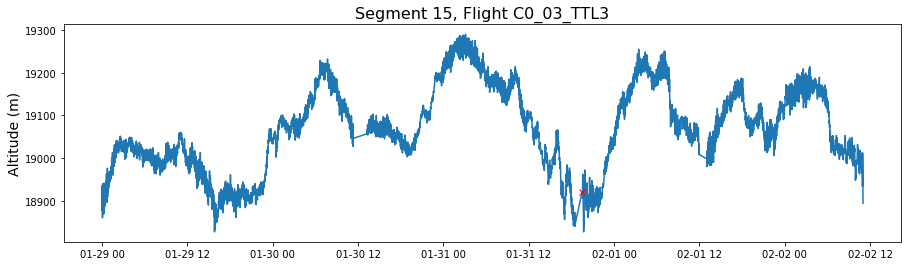

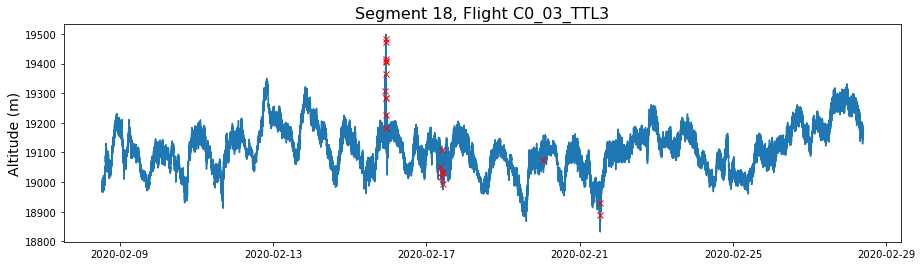

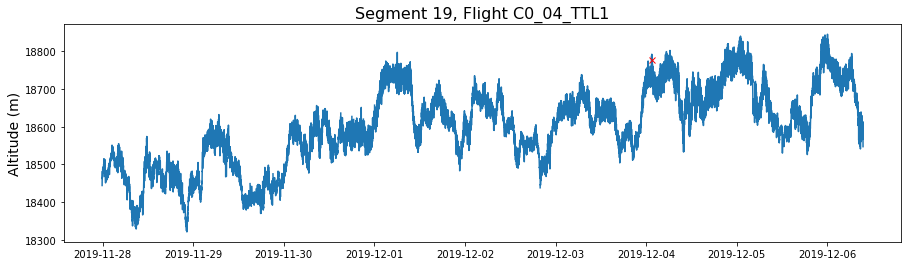

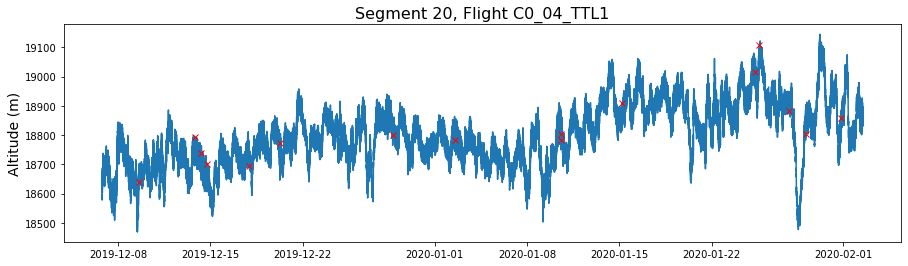

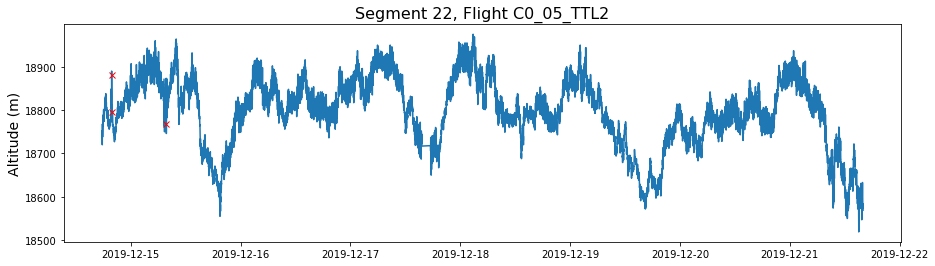

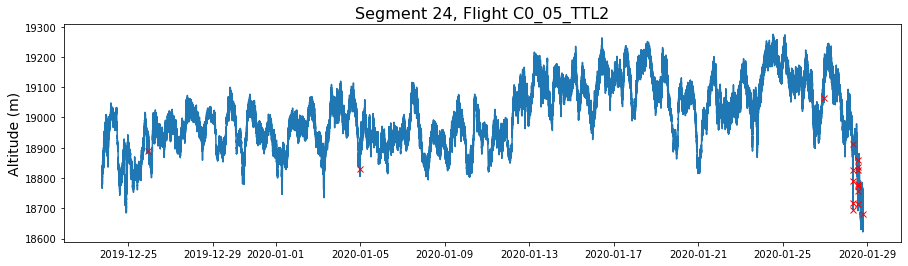

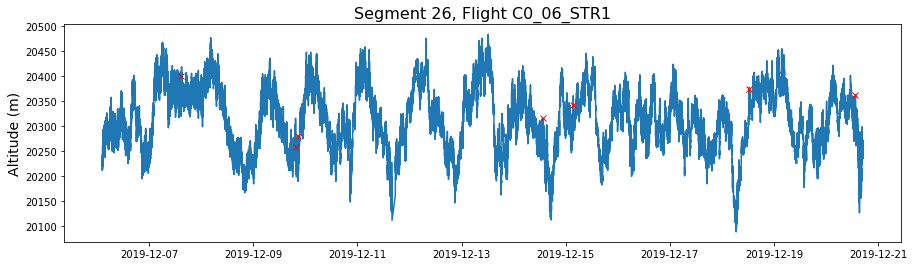

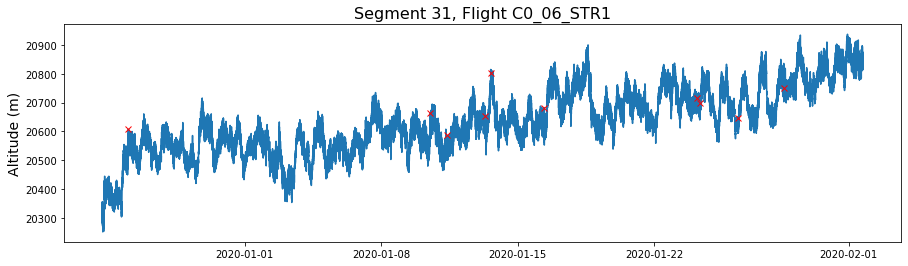

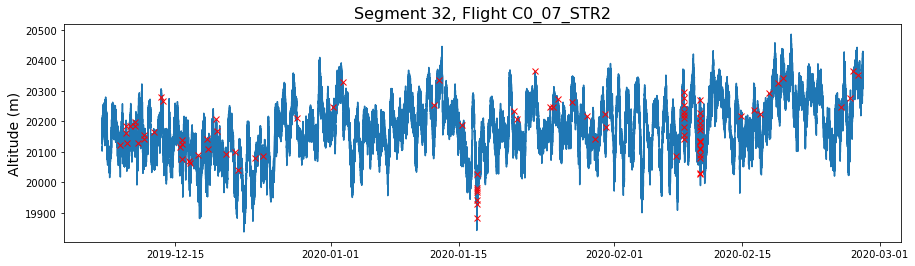

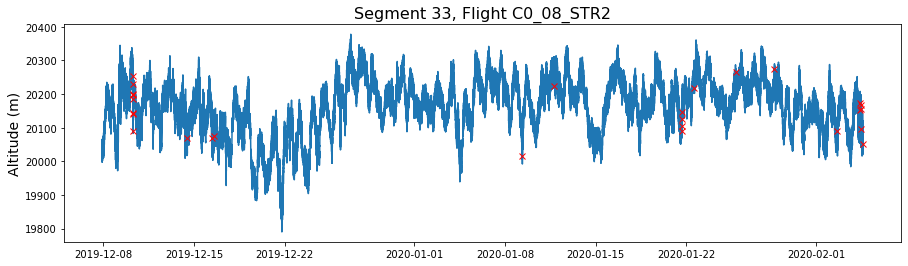

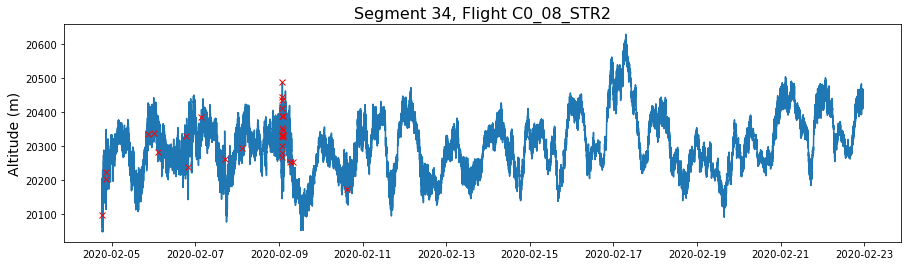

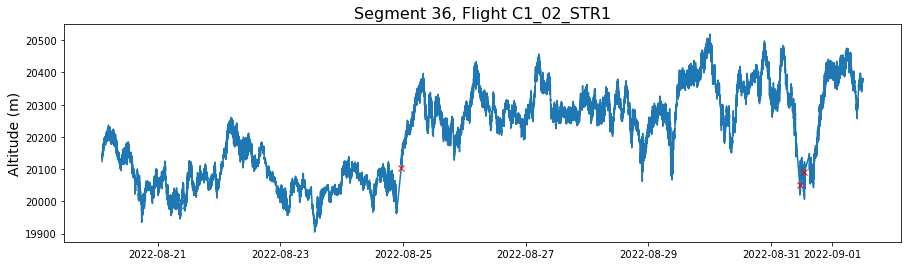

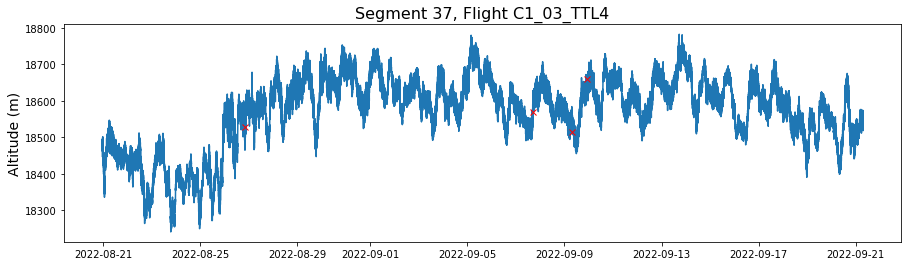

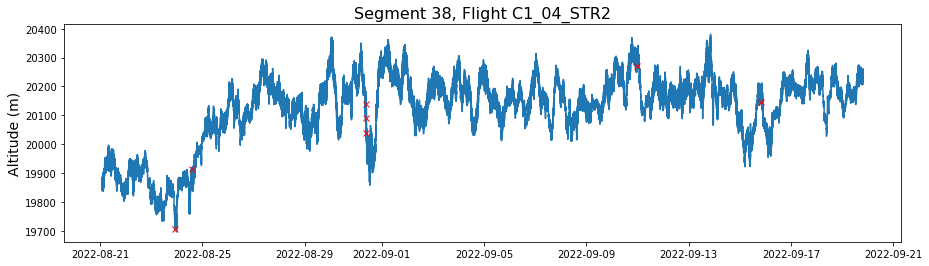

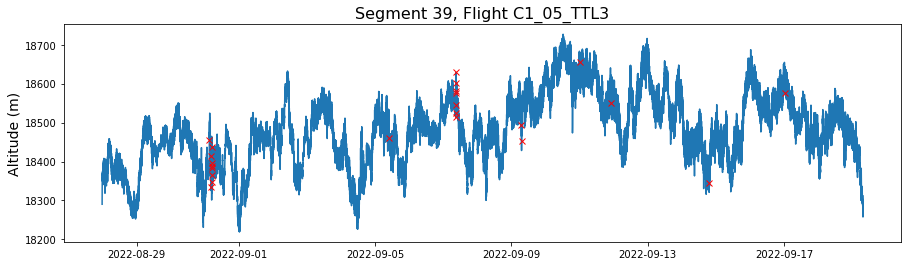

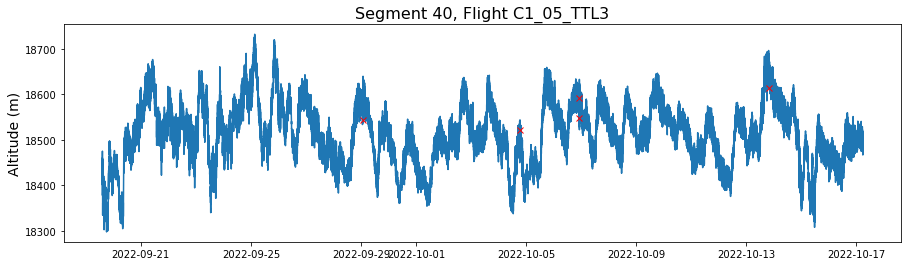

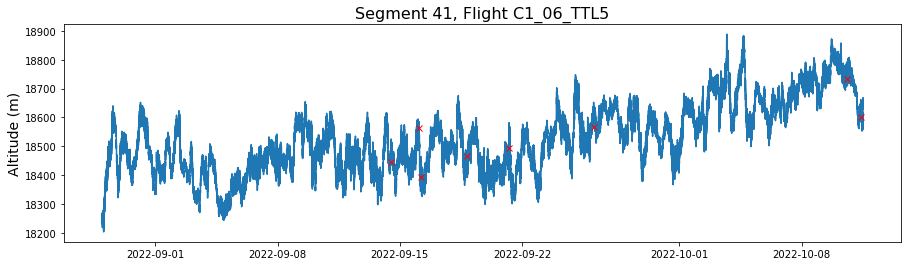

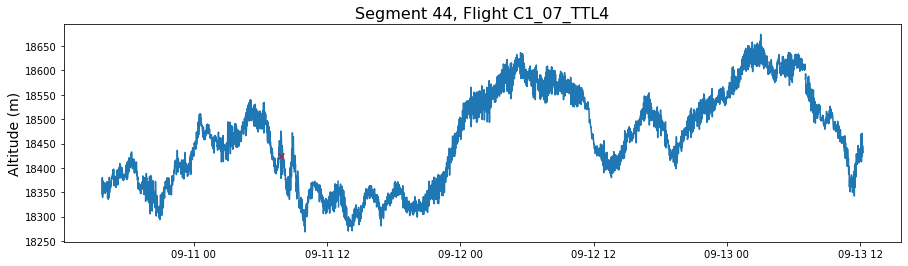

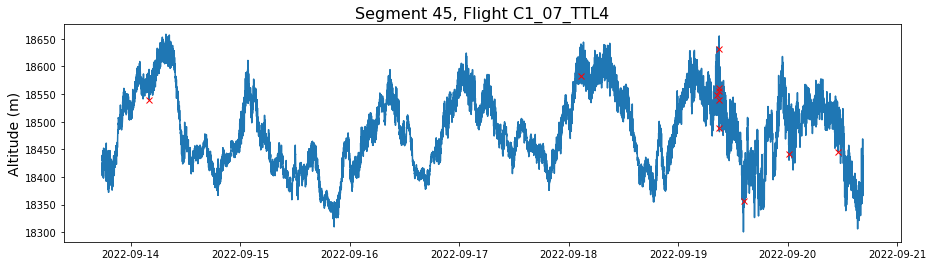

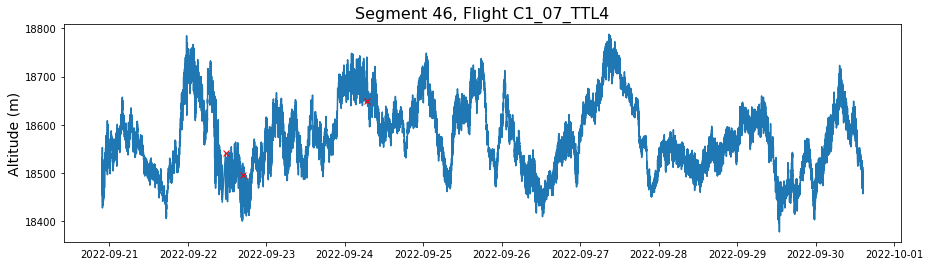

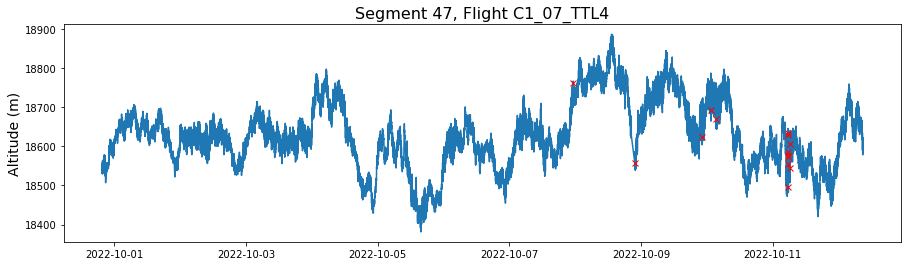

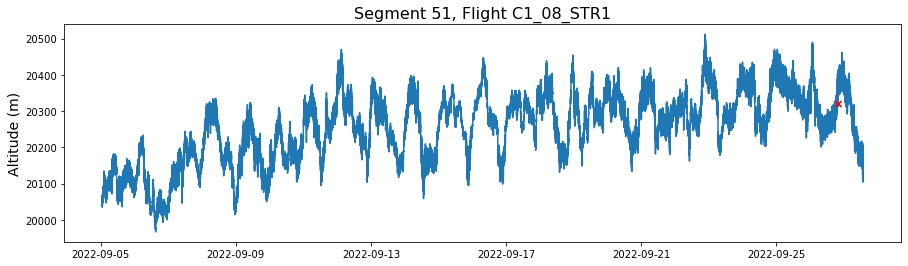

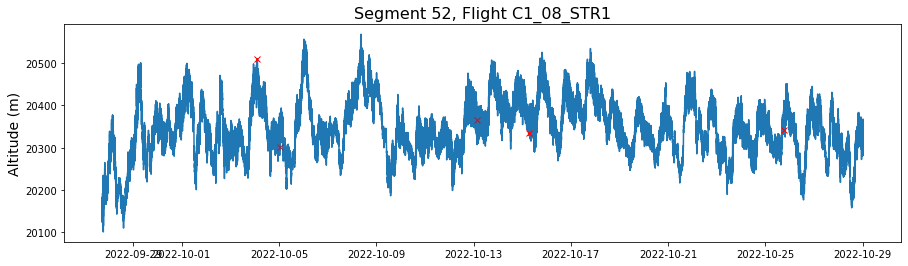

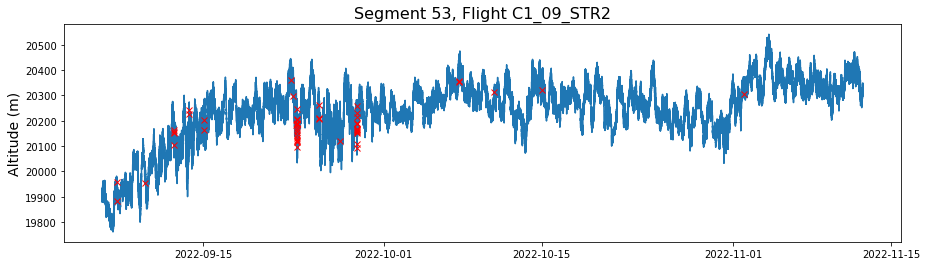

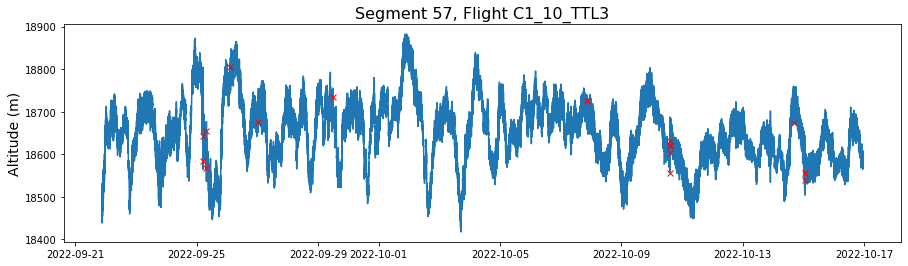

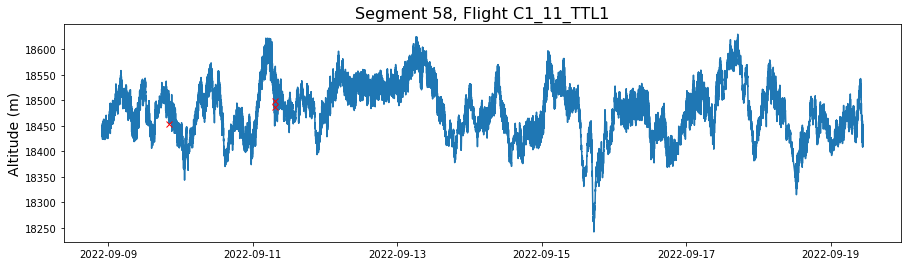

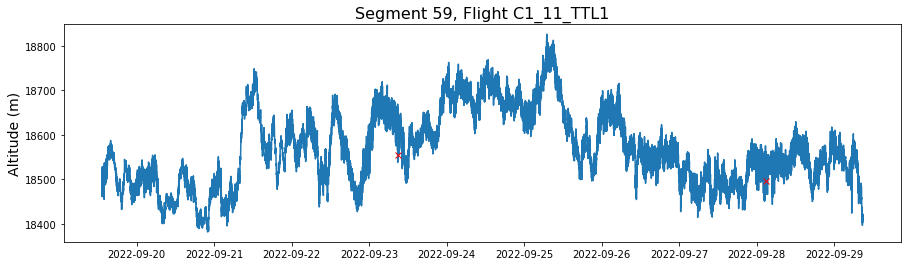

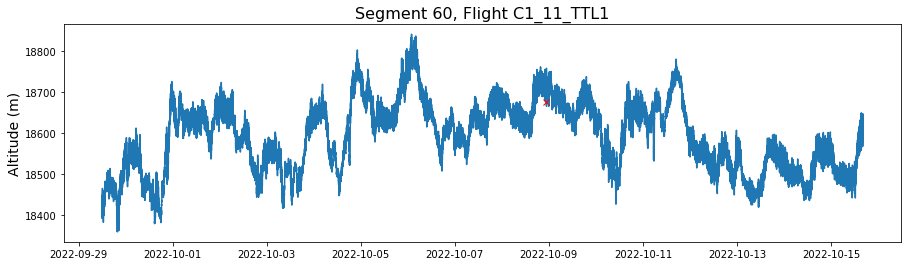

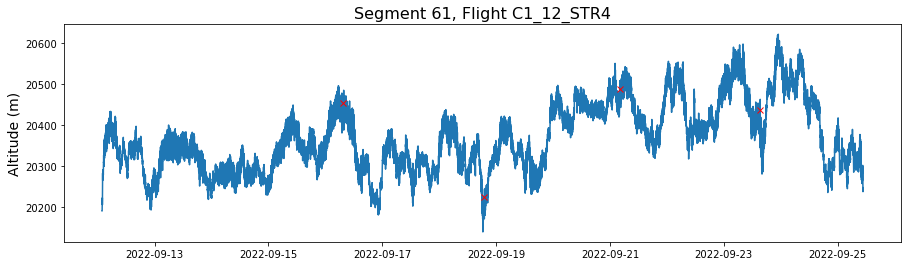

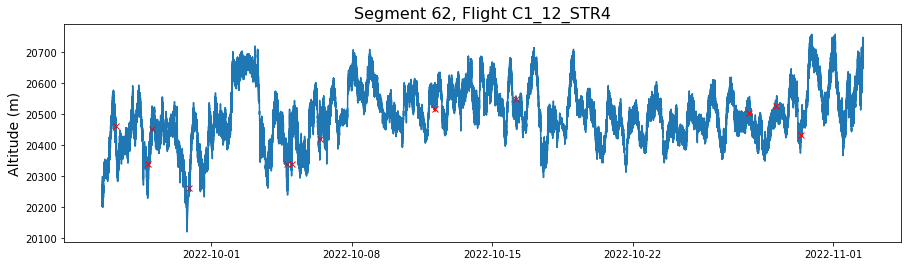

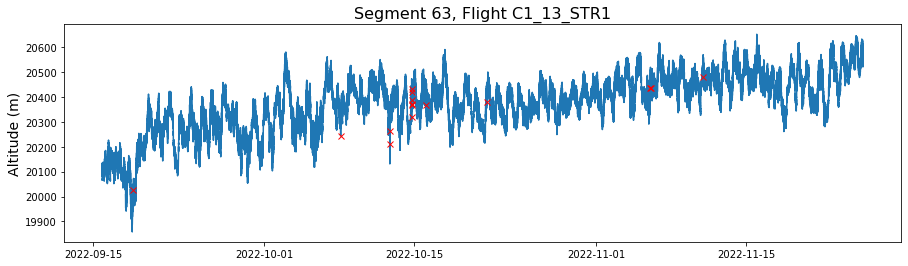

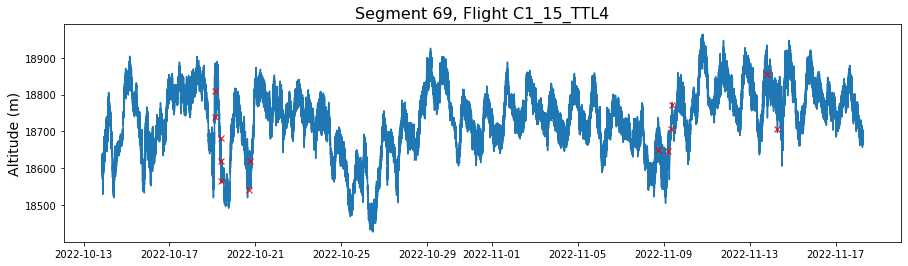

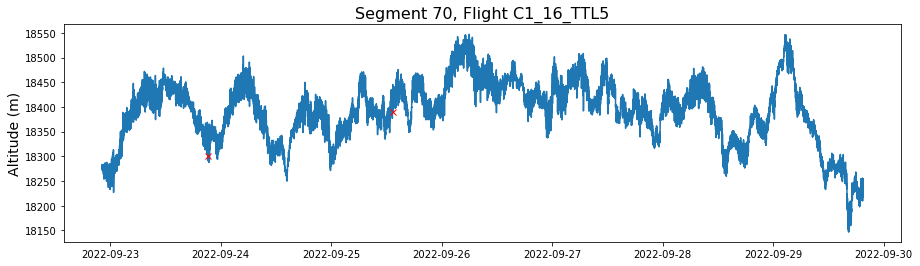

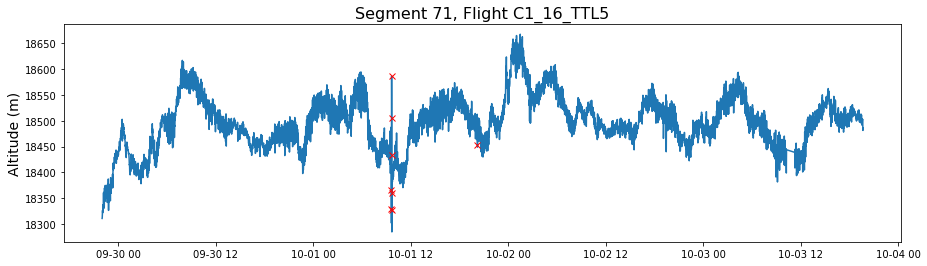

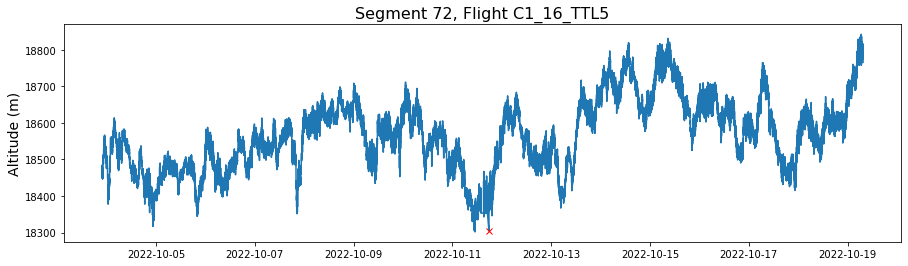

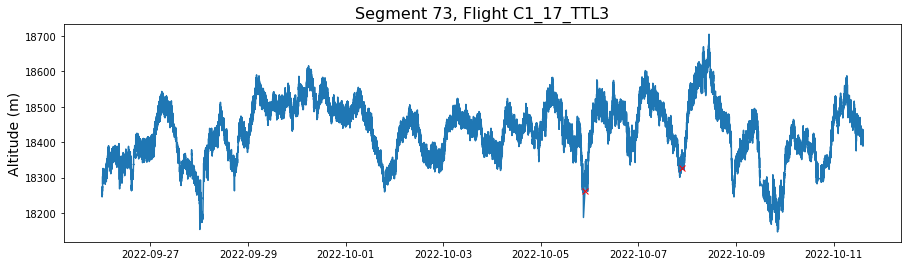

In [4]:
# Check for altitude jumps

def single_altitude_jump(segment):
    
    # Shift the values one time step so the second diff operates on the time step after a given value
    segment_shifted = segment.shift(periods=-1, axis="rows")
    alt_change = segment.loc[(segment.altitude.diff().abs() > DELTA_ALT_THRESH_JUMP)]
    
    # Mark the altitude jump
    segment['altitude_jump'] = 0
    segment.loc[alt_change.index,['altitude_jump']] = 1
    
    return segment

temp = flights.reset_index(drop=True)
flights = flights.groupby('segment_id').progress_apply(single_altitude_jump).reset_index(drop=True)

print('Number of altitude jumps:', flights.altitude_jump.sum())

# Plot the altitude jump
segments_to_plot = flights[flights.altitude_jump == 1].copy()
segments_to_plot = segments_to_plot.segment_id.unique()
for i in np.arange(segments_to_plot.size):
    segment = flights[flights.segment_id == segments_to_plot[i]]
    
    plt.figure(figsize=(15,4))
    plt.plot(segment.time,segment.altitude)
    temp = segment[segment.altitude_jump == 1]
    plt.plot(temp.time,temp.altitude,'rx')
    plt.title(f'Segment {segment.segment_id.iloc[0]}, Flight {segment.flight_id.iloc[0]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14);

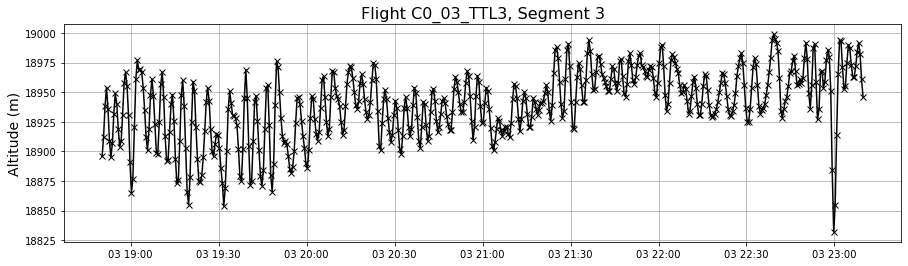

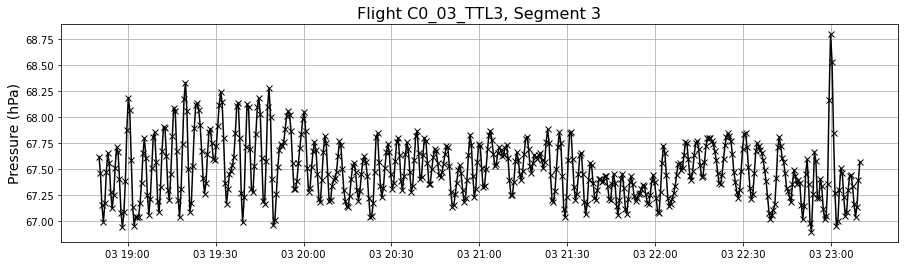

In [43]:
# Select a segment and zoom in on a specified time interval
segment_to_plot = 3

flight = flights[flights.segment_id == segment_to_plot]
#time_start = flight.time.iloc[0]
#time_stop = flight.time.iloc[-1]
time_start = pd.Timestamp('2019-12-03 18:50:00.00')
time_stop = pd.Timestamp('2019-12-03 23:10:00.00')
flight = flight[flight.time >= time_start]
flight = flight[flight.time <= time_stop]


plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.altitude,'-kx')
plt.grid()
plt.title(f'Flight {flight.flight_id.iloc[0]}, Segment {segment_to_plot}', fontsize=16)
plt.ylabel('Altitude (m)', fontsize=14);

plt.figure(figsize=(15,4))
plt.plot(flight.time,flight.pressure,'-kx')
plt.grid()
plt.title(f'Flight {flight.flight_id.iloc[0]}, Segment {segment_to_plot}', fontsize=16)
plt.ylabel('Pressure (hPa)', fontsize=14);

  0%|          | 0/57 [00:00<?, ?it/s]

Number of wind_u spikes: 15
Number of wind_v spikes: 7


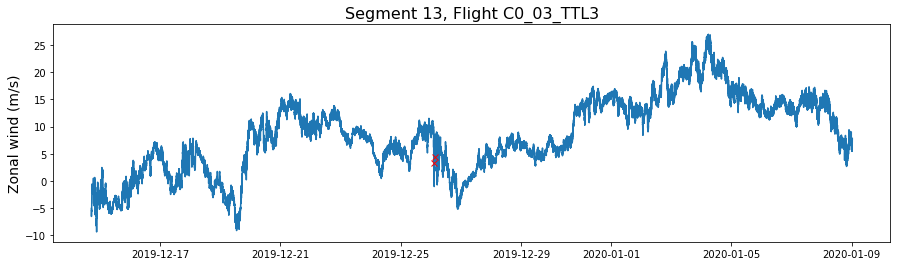

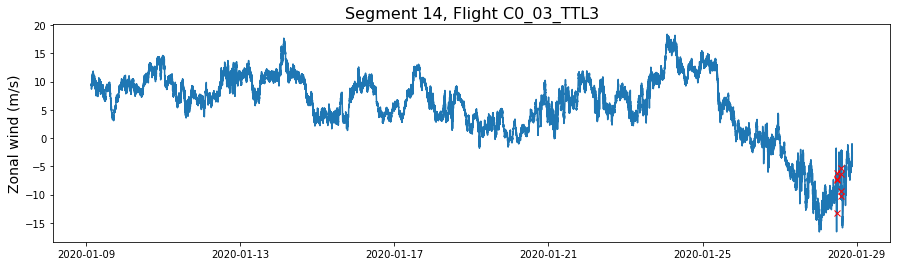

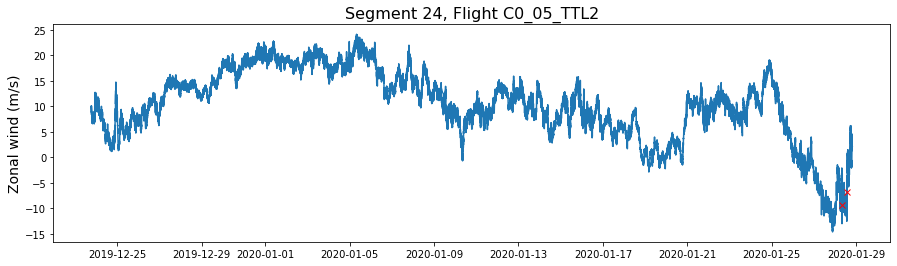

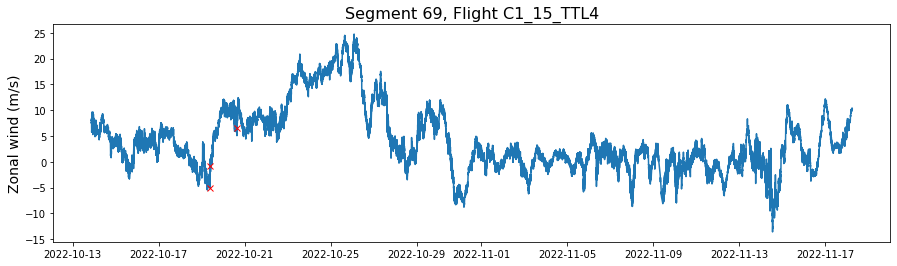

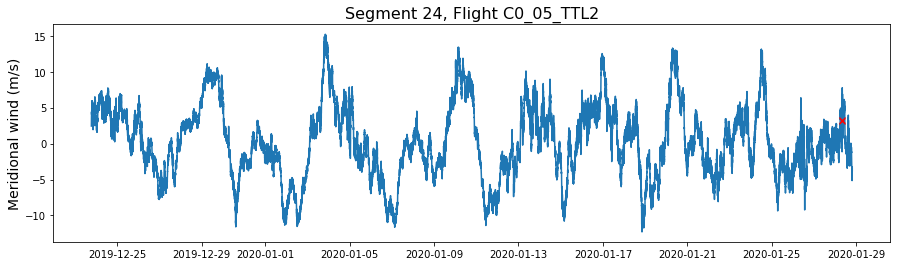

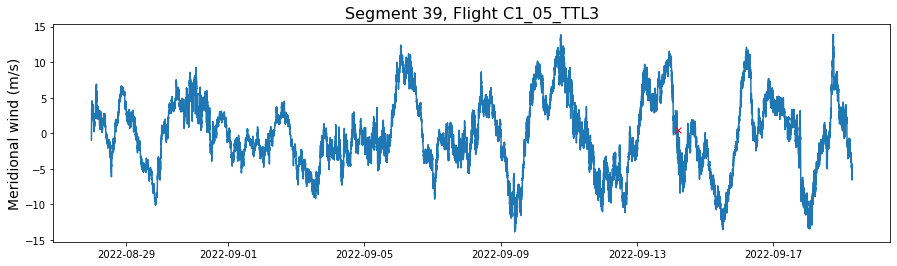

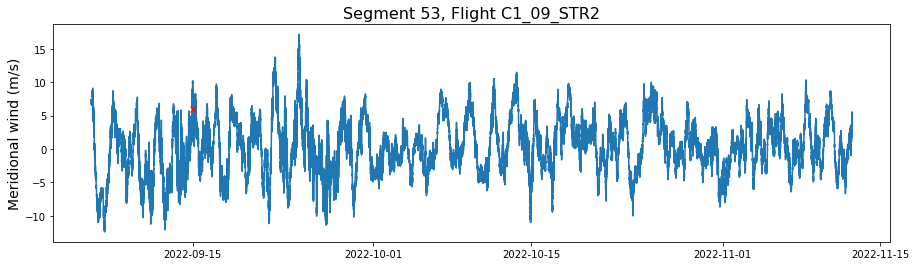

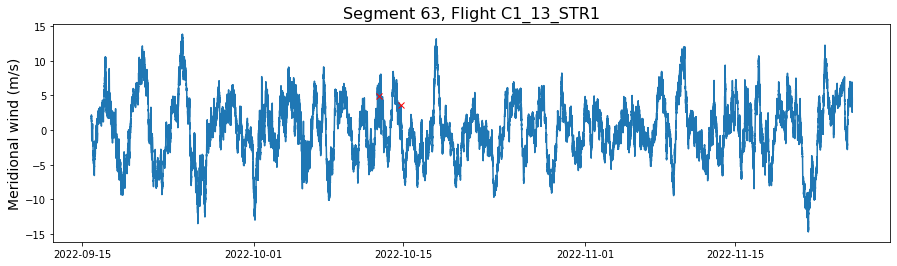

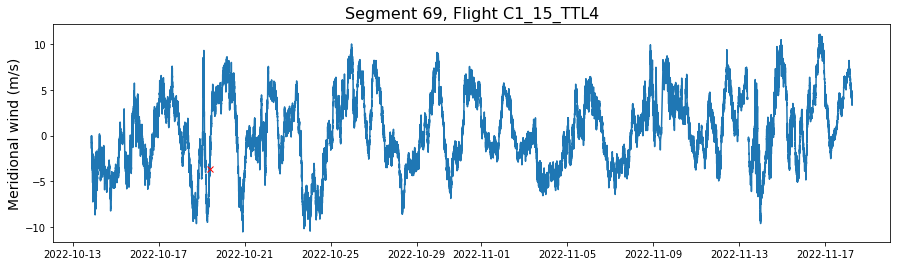

In [5]:
# Check for spikes in the wind data

def find_wind_jumps(segment):
    
    # Calculate the time step, in seconds
    segment['dt'] = segment.time.diff()/pd.Timedelta(1,'seconds')
    
    # Shift the values one time step so the second diff operates on the time step after a given value
    segment_shifted = segment.shift(periods=-1, axis="rows")
    
    # An increase from the previous value, then a decrease to the next value
    u_change1 = segment.loc[(segment.u.diff()/segment.dt > DELTA_WIND_THRESH) & 
                            (segment_shifted.u.diff()/segment_shifted.dt < -DELTA_WIND_THRESH)]
    v_change1 = segment.loc[(segment.v.diff()/segment.dt > DELTA_WIND_THRESH) & 
                            (segment_shifted.v.diff()/segment_shifted.dt < -DELTA_WIND_THRESH)]
    
    # A decrease from the previous value, then an increase to the next value
    u_change2 = segment.loc[(segment.u.diff()/segment.dt < -DELTA_WIND_THRESH) & 
                            (segment_shifted.u.diff()/segment_shifted.dt > DELTA_WIND_THRESH)]
    v_change2 = segment.loc[(segment.v.diff()/segment.dt < -DELTA_WIND_THRESH) & 
                            (segment_shifted.v.diff()/segment_shifted.dt > DELTA_WIND_THRESH)]
    
    # Mark the altitude spike
    segment['wind_spike_u'] = 0
    segment.loc[u_change1.index,['wind_spike_u']] = 1
    segment.loc[u_change2.index,['wind_spike_u']] = 1
    segment['wind_spike_v'] = 0
    segment.loc[v_change1.index,['wind_spike_v']] = 1
    segment.loc[v_change2.index,['wind_spike_v']] = 1
    
    return segment

temp = flights.reset_index(drop=True)
flights = flights.groupby('segment_id').progress_apply(find_wind_jumps).reset_index(drop=True)

print('Number of wind_u spikes:', flights.wind_spike_u.sum())
print('Number of wind_v spikes:', flights.wind_spike_v.sum())

# Plot the wind spikes
segments_to_plot = flights[flights.wind_spike_u == 1].copy()
segments_to_plot = segments_to_plot.segment_id.unique()
for i in np.arange(segments_to_plot.size):
    segment = flights[flights.segment_id == segments_to_plot[i]]
    
    plt.figure(figsize=(15,4))
    plt.plot(segment.time,segment.u)
    temp = segment[segment.wind_spike_u == 1]
    plt.plot(temp.time,temp.u,'rx')
    plt.title(f'Segment {segment.segment_id.iloc[0]}, Flight {segment.flight_id.iloc[0]}', fontsize=16)
    plt.ylabel('Zonal wind (m/s)', fontsize=14);
    
segments_to_plot = flights[flights.wind_spike_v == 1].copy()
segments_to_plot = segments_to_plot.segment_id.unique()
for i in np.arange(segments_to_plot.size):
    segment = flights[flights.segment_id == segments_to_plot[i]]
    
    plt.figure(figsize=(15,4))
    plt.plot(segment.time,segment.v)
    temp = segment[segment.wind_spike_v == 1]
    plt.plot(temp.time,temp.v,'rx')
    plt.title(f'Segment {segment.segment_id.iloc[0]}, Flight {segment.flight_id.iloc[0]}', fontsize=16)
    plt.ylabel('Meridional wind (m/s)', fontsize=14);

  0%|          | 0/57 [00:00<?, ?it/s]

Number of pressure spikes: 6


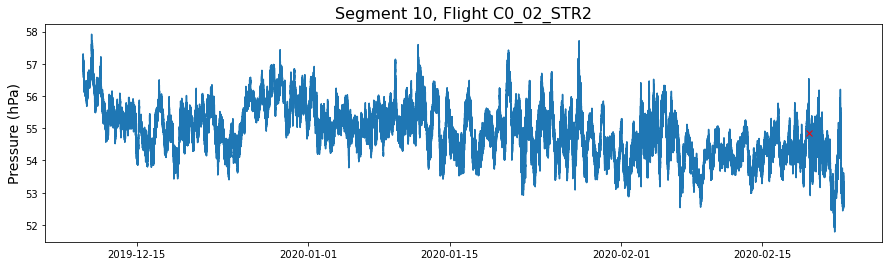

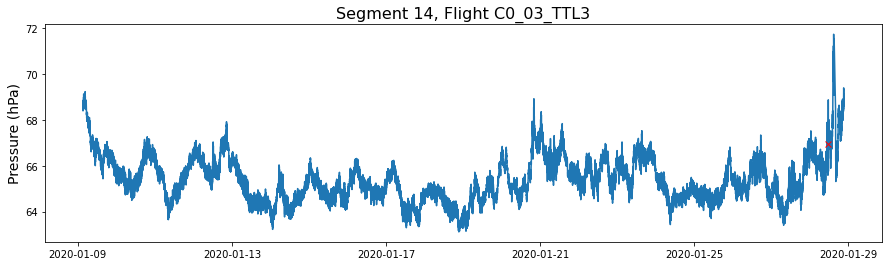

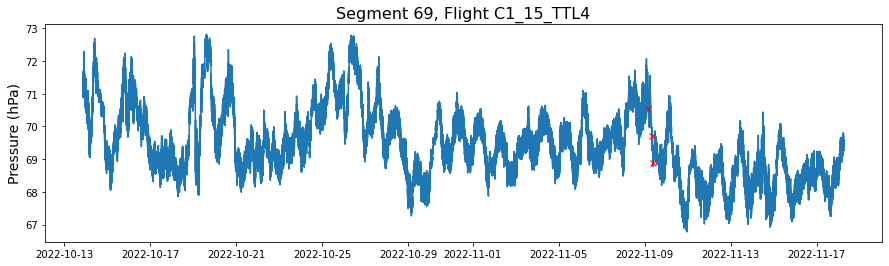

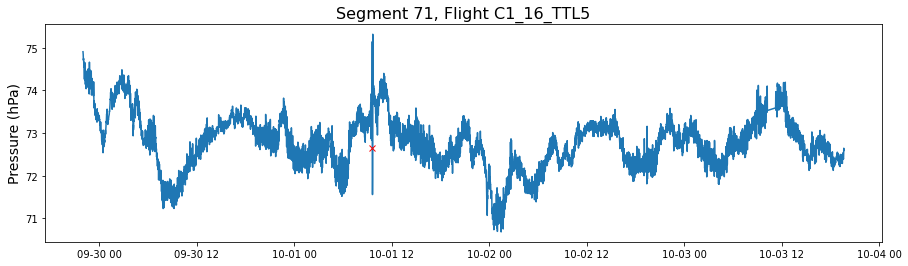

In [6]:
# Check for pressure spikes

def single_pressure_spike(segment):
    
    # Shift the values one time step so the second diff operates on the time step after a given value
    segment_shifted = segment.shift(periods=-1, axis="rows")
    # An increase from the previous value, then a decrease to the next value
    p_change1 = segment.loc[(segment.pressure.diff() > DELTA_P_THRESH) & 
                            (segment_shifted.pressure.diff() < -DELTA_P_THRESH)]
    # A decrease from the previous value, then an increase to the next value
    p_change2 = segment.loc[(segment.pressure.diff() < -DELTA_P_THRESH) & 
                            (segment_shifted.altitude.diff() > DELTA_P_THRESH)]
    # Mark the altitude spike
    segment['pressure_spike'] = 0
    segment.loc[p_change1.index,['pressure_spike']] = 1
    segment.loc[p_change2.index,['pressure_spike']] = 1
    
    return segment

temp = flights.reset_index(drop=True)
flights = flights.groupby('segment_id').progress_apply(single_pressure_spike).reset_index(drop=True)

print('Number of pressure spikes:', flights.pressure_spike.sum())

# Plot the pressure spikes
segments_to_plot = flights[flights.pressure_spike == 1].copy()
segments_to_plot = segments_to_plot.segment_id.unique()
for i in np.arange(segments_to_plot.size):
    segment = flights[flights.segment_id == segments_to_plot[i]]
    
    plt.figure(figsize=(15,4))
    plt.plot(segment.time,segment.pressure)
    temp = segment[segment.pressure_spike == 1]
    plt.plot(temp.time,temp.pressure,'rx')
    plt.title(f'Segment {segment.segment_id.iloc[0]}, Flight {segment.flight_id.iloc[0]}', fontsize=16)
    plt.ylabel('Pressure (hPa)', fontsize=14);